# Monitoraggio dell'umidità del suolo da sensori IoT
Un consorzio agricolo del nord Sardegna ha installato sensori di umidità del suolo in 20 campi di diverse colture. Le letture arrivano ogni 15 minuti. A partire dai dati di luglio 2025 (simulati), l'analisi risponde a quattro domande:
1. Quali campi hanno dati affidabili?
2. Ci sono sensori probabilmente mal calibrati?
3. Quali colture hanno sofferto di più lo stress idrico?
4. Quali campi hanno diritto al contributo per l'irrigazione di soccorso (almeno 10 giorni consecutivi di stress)?

# 1. ======================== CARICARE E ISPEZIONARE LE TABELLE ========================

In [1]:
# Import delle librerie
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# Caricare i dataset
campi = pd.read_csv("dati/campi.csv")
sensori = pd.read_csv("dati/sensori.csv")
letture = pd.read_csv("dati/letture.csv", parse_dates=["data_ora"])

In [3]:
# Ispezionare la tabella letture
print("------- LETTURE -------")
letture.info()
print("\nNumero di valori mancanti:")
print(letture.isna().sum())
print(f'\nNumero di righe duplicate: {letture.duplicated().sum()}')


# Ispezionare la tabella campi
print("\n------- CAMPI -------")
campi.info()
print("\nNumero di valori mancanti:")
print(campi.isna().sum())
print(f'\nNumero di righe duplicate: {campi.duplicated().sum()}')

print("\n------- SENSORI -------")
sensori.info()
print("\nNumero di valori mancanti:")
print(sensori.isna().sum())
print(f'\nNumero di righe duplicate: {sensori.duplicated().sum()}')


------- LETTURE -------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 156480 entries, 0 to 156479
Data columns (total 3 columns):
 #   Column         Non-Null Count   Dtype         
---  ------         --------------   -----         
 0   id_sensore     156480 non-null  int64         
 1   data_ora       156480 non-null  datetime64[ns]
 2   umidita_suolo  155685 non-null  float64       
dtypes: datetime64[ns](1), float64(1), int64(1)
memory usage: 3.6 MB

Numero di valori mancanti:
id_sensore         0
data_ora           0
umidita_suolo    795
dtype: int64

Numero di righe duplicate: 0

------- CAMPI -------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id_campo       20 non-null     int64  
 1   comune         20 non-null     object 
 2   coltura        20 non-null     object 
 3   superficie_ha  20 non-null     float64
dtypes: float6

Nella tabella letture ci sono 795 valori mancanti per la colonna umidità del suolo, probabilmente dovuti ad una data antecedente a quella di installazione del sensore o a problemi di funzionamento.

# 2. ======================== QUALITÀ DEI DATI ========================

In [4]:
# Recuperare solo i sensori attivi a luglio
# Selezionare solo le letture di luglio
letture_luglio = letture[(letture["data_ora"] >= "2025-07-01") & (letture["data_ora"] < "2025-08-01")]
print("\n------- LETTURE LUGLIO 2025 -------")
print(f'Numero di letture a luglio 2025: {len(letture_luglio)}')

# Calcolare il numero di letture per sensore a luglio
letture_luglio_per_sensore = letture_luglio.groupby("id_sensore").size().reset_index(name="n_letture")

# Unire la tabella delle letture per sensore con la tabella sensori per recuperare l'identificativo di ogni campo
sensori_luglio = pd.merge(letture_luglio_per_sensore, sensori, on="id_sensore")
sensori_luglio = sensori_luglio[["id_sensore", "id_campo", "n_letture"]]

# Calcolare i sensori attivi a luglio per campo
sensori_luglio_per_campo = sensori_luglio.groupby("id_campo").size().reset_index(name="n_sensori_attivi")

# Filtrare i campi con almeno 2 sensori attivi a luglio
campi_validi = sensori_luglio_per_campo[sensori_luglio_per_campo["n_sensori_attivi"] >= 2]
print(f'Numero di campi con almeno 2 sensori attivi a luglio 2025: {len(campi_validi)}')

# Unire la tabella delle letture di luglio con la tabella sensori per recuperare l'identificativo del campo
luglio_con_campo = pd.merge(letture_luglio, sensori, on="id_sensore")
luglio_con_campo = luglio_con_campo[["id_sensore", "data_ora", "umidita_suolo", "id_campo"]]     

# Unire la tabella luglio con campo con la tabella campi validi per recuperare solo letture di luglio 2025 dei campi con almeno 2 sensori attivi
letture_valide = pd.merge(luglio_con_campo, campi_validi, on="id_campo")
print(f'Numero di letture totali dei campi con almeno 2 sensori attivi a luglio: {len(letture_valide)}')

# Aggiungere la colonna giorno alla tabella letture valide
letture_valide["giorno"] = letture_valide["data_ora"].dt.date
letture_valide = letture_valide[["id_sensore", "id_campo", "giorno", "n_sensori_attivi", "umidita_suolo"]]


------- LETTURE LUGLIO 2025 -------
Numero di letture a luglio 2025: 115200
Numero di campi con almeno 2 sensori attivi a luglio 2025: 17
Numero di letture totali dei campi con almeno 2 sensori attivi a luglio: 106272


In [5]:
# Unire la tabella letture luglio per sensore e la tabella sensori
sensori_esclusi = pd.merge(sensori, letture_luglio_per_sensore, on="id_sensore", how="left")

# Tenere solo i sensori dei campi esclusi dall'analisi
sensori_esclusi = sensori_esclusi[~sensori_esclusi["id_campo"].isin(campi_validi["id_campo"])]
sensori_esclusi

,id_sensore,id_campo,data_installazione,n_letture
10,111,6,2024-04-13,2976.0
24,125,13,2024-03-26,2976.0
25,126,13,2025-08-02,NaN
30,131,16,2024-06-12,NaN
31,132,16,2024-06-25,2976.0


In [6]:
# Recuperare l'ultima lettura valida del sensore 131 (campo 16)
sensore_131 = letture[letture["id_sensore"] == 131].tail(1)
sensore_131

,id_sensore,data_ora,umidita_suolo
117599,131,2025-06-27 23:45:00,0.166


### Campi esclusi dall'analisi
Per l'analisi sono stati considerati solo i campi con **almeno 2 sensori attivi a luglio 2025**, così da poter confrontare le letture tra sensori dello stesso campo. Tre campi su 20 sono stati esclusi:
- **Campo 6**: ha un solo sensore (111), quindi non è possibile confrontare le sue letture con quelle di un altro.
- **Campo 13**: ha due sensori, ma il 126 è stato installato il 2 agosto 2025; a luglio era attivo solo il 125.
- **Campo 16**: ha due sensori (131 e 132) ma il 131, pur essendo installato da giugno 2024, non ha nessuna lettura a luglio. Nei dati grezzi la sua ultima lettura è del 27 giugno 2025, il che suggerisce un guasto o uno scollegamento del sensore.

# 3. ======================== STRESS IDRICO PER COLTURA ========================

In [7]:
# Calcolare l'umidità media giornaliera a luglio 2025 dei singoli campi con almeno 2 sensori attivi
umidita_giornaliera = letture_valide.groupby(["id_campo", "giorno"])["umidita_suolo"].mean().reset_index(name="umidita_suolo_media")

# Aggiungere la colonna stress per determinare la presenza o assenza di stress in campo (0 = assenza di stress, 1 = presenza di stress)
umidita_giornaliera["stress"] = (umidita_giornaliera["umidita_suolo_media"] < 0.15).astype(int)
print("\n------- STRESS IDRICO PER CAMPO -------")
print(f'Giorni-campo con stress idrico a luglio 2025: {umidita_giornaliera["stress"].value_counts().loc[1]}')

# Calcolare i giorni di stress per campo
giorni_stress_luglio = umidita_giornaliera.groupby("id_campo")["stress"].sum().reset_index(name="giorni_stress")
print("\nGiorni di stress per campo a luglio 2025:")
print(giorni_stress_luglio)


------- STRESS IDRICO PER CAMPO -------
Giorni-campo con stress idrico a luglio 2025: 172

Giorni di stress per campo a luglio 2025:
    id_campo  giorni_stress
0          1             16
1          2             16
2          3             28
3          4              0
4          5             11
5          7             14
6          8              6
7          9             10
8         10             12
9         11             19
10        12              0
11        14              8
12        15             16
13        17              0
14        18             16
15        19              0
16        20              0


In [8]:
# Calcolare la media dei giorni di stress per comune e coltura
media_per_coltura = pd.merge(giorni_stress_luglio, campi, on="id_campo")
media_per_coltura = media_per_coltura.groupby(["comune", "coltura"])["giorni_stress"].mean().reset_index(name="media_giorni_stress")
print("\n------- STRESS IDRICO PER COMUNE E COLTURA -------")
print("\nMedia dei giorni di stress per comune e coltura:")
print(media_per_coltura)

# Ordinare la tabella per la media dei giorni di stress 
top_stress_coltura = media_per_coltura.sort_values(["comune", "media_giorni_stress"], ascending=[True, False])

# Calcolare la coltura con il maggior numero di giorni di stress per ogni comune
coltura_vincente = top_stress_coltura.groupby("comune").head(1)
print("\nColtura con la più alta media giorni di stress per ogni comune:")
print(coltura_vincente)


------- STRESS IDRICO PER COMUNE E COLTURA -------

Media dei giorni di stress per comune e coltura:
         comune     coltura  media_giorni_stress
0       Alghero    carciofo                 11.0
1       Alghero    pomodoro                 14.0
2       Alghero        vite                 16.0
3  Porto Torres    carciofo                 12.0
4  Porto Torres  grano duro                  8.0
5  Porto Torres        mais                  0.0
6  Porto Torres        vite                  0.0
7       Sassari  grano duro                 19.0
8       Sassari        mais                 10.5
9       Sassari    pomodoro                  0.0

Coltura con la più alta media giorni di stress per ogni comune:
         comune     coltura  media_giorni_stress
2       Alghero        vite                 16.0
3  Porto Torres    carciofo                 12.0
7       Sassari  grano duro                 19.0


# 4. ======================== SENSORI IN DISACCORDO ========================

In [9]:
# Calcolare la media di umidità del suolo per sensore x giorno x campo
media_per_sensore = letture_valide.groupby(["id_sensore", "id_campo", "giorno"])["umidita_suolo"].mean().reset_index(name="umidita_suolo_media")

# Calcolare il numero di sensori per campo x giorno, il valore massimo e minimo di umidità media del suolo
estremi_giornalieri = media_per_sensore.groupby(["id_campo", "giorno"]).agg(umidita_suolo_media_max =("umidita_suolo_media", "max"),
                                                                            umidita_suolo_media_min =("umidita_suolo_media", "min"), n_sensori_giorno =("id_sensore", "count")
                                                                            ).reset_index()

# Filtrare per i campi che hanno minimo 2 sensori x giorno
giorni_confrontabili = estremi_giornalieri[estremi_giornalieri["n_sensori_giorno"] >= 2].copy()

# Calcolare il disaccordo x giorno come differenza tra media di umidità massima e minima per ogni campo x giorno
giorni_confrontabili["disaccordo_giorno"] = giorni_confrontabili["umidita_suolo_media_max"] - giorni_confrontabili["umidita_suolo_media_min"]
giorni_confrontabili = giorni_confrontabili[["id_campo", "giorno", "disaccordo_giorno"]]

# Calcolare la media del disaccordo per campo
disaccordo_per_campo = giorni_confrontabili.groupby("id_campo")["disaccordo_giorno"].mean().reset_index(name="disaccordo_campo")
print("------- DISACCORDO PER CAMPO -------")
print(disaccordo_per_campo)

# Unire la tabella disaccordo per campo con la tabella campi per recuperare comune e coltura dei campi
top_disaccordo = pd.merge(disaccordo_per_campo, campi, on="id_campo")
top_disaccordo = top_disaccordo[["id_campo", "comune", "coltura", "disaccordo_campo"]]

# Ordinare la tabella in base al disaccordo x campo in ordine decrescente
top_5_disaccordo = top_disaccordo.sort_values(["disaccordo_campo"], ascending=[False]).head(5)
print("\nI 5 campi con il maggiore disaccordo:")
print(top_5_disaccordo)

------- DISACCORDO PER CAMPO -------
    id_campo  disaccordo_campo
0          1          0.006011
1          2          0.001114
2          3          0.015010
3          4          0.002004
4          5          0.017938
5          7          0.005995
6          8          0.007071
7          9          0.011034
8         10          0.004011
9         11          0.019015
10        12          0.007970
11        14          0.003957
12        15          0.003998
13        17          0.005962
14        18          0.005011
15        19          0.018889
16        20          0.005982

I 5 campi con il maggiore disaccordo:
    id_campo        comune     coltura  disaccordo_campo
9         11       Sassari  grano duro          0.019015
15        19  Porto Torres  grano duro          0.018889
4          5       Alghero    carciofo          0.017938
2          3       Alghero    pomodoro          0.015010
7          9       Sassari        mais          0.011034


# 5. ======================== STRESS PROLUNGATO E CONTRIBUTO ========================

Il consorzio concede un contributo per l’irrigazione di soccorso ai campi che a luglio hanno avuto almeno 10 giorni consecutivi di stress. Per ogni campo valido è richiesto:
a) il primo giorno di stress di luglio;
b) la serie più lunga di giorni consecutivi di stress;
c) se ha diritto al contributo.

In [10]:
# Filtrare solo per i giorni di stress (stress = 1)
giorni_con_stress = umidita_giornaliera[umidita_giornaliera["stress"] == 1].copy()

# Ottenere il primo giorno di stress per ogni campo
primo_giorno_stress = giorni_con_stress.groupby("id_campo")["giorno"].min().reset_index(name="inizio_stress")
print("------- SERIE DI GIORNI DI STRESS -------")
print("\nPrimo giorno di stress per ogni campo:")
print(primo_giorno_stress)

# Unire la tabella con il primo giorno di stress con campi validi per recuperare i campi esclusi dal filtro
campi_stress = pd.merge(campi_validi, primo_giorno_stress, on="id_campo", how="left")

# Ordinare la tabella umidità giornaliera per campo e per giorno
umidita_giornaliera= umidita_giornaliera.sort_values(["id_campo", "giorno"])

# Creare un lag di 1 giorno nella tabella umidità giornaliera per trovare l'inizio di una nuova serie
umidita_giornaliera["stress_ieri"]= umidita_giornaliera.groupby("id_campo")["stress"].shift(1, fill_value=0)

# Creare una nuova colonna per individuare l'inizio di ogni nuova serie
umidita_giornaliera["inizio_serie"] = ((umidita_giornaliera["stress"] == 1) & (umidita_giornaliera["stress_ieri"] == 0)).astype(int)
print(f'\nNumero di serie di giorni di stress: {umidita_giornaliera["inizio_serie"].sum()}')

# Numerare le serie per misurarne la lunghezza
umidita_giornaliera["id_serie"] = umidita_giornaliera.groupby("id_campo")["inizio_serie"].cumsum()

# Filtrare solo per le righe con stress = 1
giorni_in_stress = umidita_giornaliera[umidita_giornaliera["stress"] == 1].copy()

# Calcolare la lunghezza di ogni serie per campo
serie = giorni_in_stress.groupby(["id_campo", "id_serie"]).size().reset_index(name="lunghezza")

# Ottenere una riga per campo con la serie più lunga
serie_max_per_campo= serie.groupby("id_campo")["lunghezza"].max().reset_index(name="max_serie_stress")

# Aggiungere una nuova colonna per verificare i campi che hanno i requisiti per ottenere il contributo
serie_max_per_campo["contributo"] = (serie_max_per_campo["max_serie_stress"] >= 10).astype(int)

------- SERIE DI GIORNI DI STRESS -------

Primo giorno di stress per ogni campo:
    id_campo inizio_stress
0          1    2025-07-16
1          2    2025-07-16
2          3    2025-07-02
3          5    2025-07-21
4          7    2025-07-18
5          8    2025-07-26
6          9    2025-07-22
7         10    2025-07-20
8         11    2025-07-11
9         14    2025-07-24
10        15    2025-07-16
11        18    2025-07-16

Numero di serie di giorni di stress: 14


In [11]:
# Creare la tabella finale con primo giorno di stress, campi e colonna stress, lunghezza serie e colonna contributo
print("------- REPORT FINALE -------")
report = pd.merge(campi_stress, serie_max_per_campo, on="id_campo", how="left")
report["max_serie_stress"] = report["max_serie_stress"].fillna(0)
report["max_serie_stress"] = report["max_serie_stress"].astype(int)
report["contributo"] = report["contributo"].fillna(0)
report["contributo"] = report["contributo"].astype(int)
print(report)

------- REPORT FINALE -------
    id_campo  n_sensori_attivi inizio_stress  max_serie_stress  contributo
0          1                 2    2025-07-16                16           1
1          2                 2    2025-07-16                16           1
2          3                 2    2025-07-02                16           1
3          4                 2           NaN                 0           0
4          5                 2    2025-07-21                11           1
5          7                 2    2025-07-18                14           1
6          8                 3    2025-07-26                 6           0
7          9                 2    2025-07-22                10           1
8         10                 2    2025-07-20                12           1
9         11                 2    2025-07-11                16           1
10        12                 2           NaN                 0           0
11        14                 2    2025-07-24                 8        

# 6. ======================== ANDAMENTO DELL'UMIDITÀ ========================

Per mostrare l'andamento dell'umidità nel tempo sono stati selezionati 4 campi su 17, per rendere il grafico più leggibile, con pattern di umidità distinti:
- Campo 4: non presenta mai condizioni di stress idrico
- Campo 3: presenta il maggiore stress idrico
- Campo 11: mostra uno stress precoce (dall'11 luglio)
- Campo 9: al limite del contributo con una serie di 10 giorni di stress

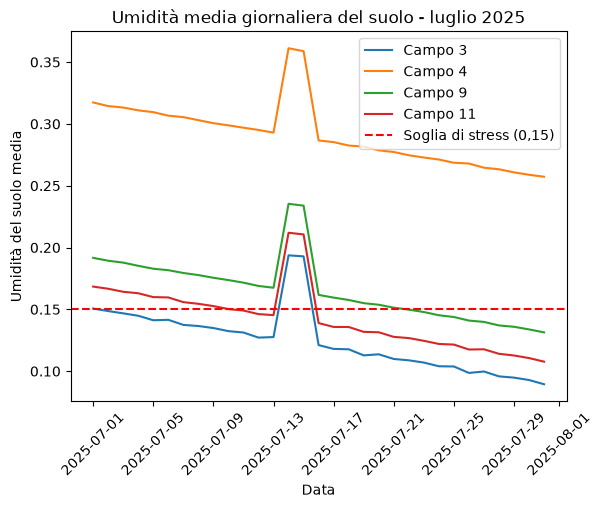

In [12]:
# Creare un grafico che confronti l'umidità del suolo dei campi
# Selezionare 4 campi per il grafico
campi_per_grafico = umidita_giornaliera[umidita_giornaliera["id_campo"].isin([3, 4, 11, 9])]

# Disegnare una linea per ogni campo
for id_campo, dati_campo in campi_per_grafico.groupby("id_campo"):
    plt.plot(dati_campo["giorno"], dati_campo["umidita_suolo_media"], label=f"Campo {id_campo}")

# Creare e salvare il grafico
plt.axhline(0.15, color="red", linestyle="--", label="Soglia di stress (0,15)")
plt.title("Umidità media giornaliera del suolo - luglio 2025")
plt.xlabel("Data")
plt.ylabel("Umidità del suolo media")
plt.legend()
plt.xticks(rotation=45)
plt.savefig("grafici/umidita_giornaliera.png", dpi=150, bbox_inches="tight")
plt.show()

### Interpretazione del grafico
Il 14 e 15 luglio l'umidità aumenta in tutti i campi, probabilmente per una pioggia, che interrompe le serie di giorni di stress. Dal 16 luglio l'umidità torna a scendere: i campi 3 e 11, già sotto soglia prima della pioggia (rispettivamente dal 2 e dall'11 luglio), tornano subito in stress e ci rimangono fino a fine mese.
Il campo 9 scende sotto soglia più tardi, il 22 luglio: la sua serie di stress dura esattamente 10 giorni, il minimo richiesto per il contributo.
Il campo 4 resta sempre sopra la soglia e non va mai in stress idrico.

## Conclusioni
1. **Affidabilità dei dati**: dei 20 campi iniziali solo 17 sono stati utilizzati per l'analisi. I 3 campi esclusi sono i **campi 6, 13 e 16** perché non avevano almeno 2 sensori attivi a luglio.
2. **Possibili sensori mal calibrati**: i campi che presentano possibili problemi di sensori mal calibrati sono i campi 11, 19, 5 e 3 con una media di disaccordo tra 0,015 e 0,019, contro la maggior parte degli altri campi che hanno valori di circa 0,005. Questi sensori andrebbero verificati in campo.
3. **Colture più stressate**: la coltura più stressata per il comune di **Alghero è la vite** con una media di 16 giorni di stress, per **Porto Torres è il carciofo** con 12 giorni e per **Sassari è il grano duro** con 19 giorni.
4. **Contributo per l'irrigazione di soccorso**: 10 dei 17 campi analizzati hanno una serie di almeno 10 giorni di stress idrico consecutivi e hanno dunque diritto al contributo. I campi sono il **campo 1, 2, 3, 5, 7, 9, 10, 11, 15 e 18.**

## Limiti
- **I dati utilizzati per questa analisi sono simulati**, perciò i risultati ottenuti non descrivono una situazione reale: l'obiettivo è mostrare il metodo di analisi.
- L'incremento di umidità del suolo osservato il 14 e il 15 luglio 2025 è stato spiegato come una possibile conseguenza di una pioggia, ma il dato non è stato verificato con dati meteorologici.
- Per calcolare le condizioni di stress idrico è stata utilizzata una soglia di riferimento di 0,15. Questo valore può tuttavia variare a seconda di diversi fattori come coltura e tipologia di suolo.
- Il disaccordo dei sensori è stato calcolato come differenza tra il valore massimo e il valore minimo di umidità media del suolo rilevata in ogni campo, ma non permette di identificare quale sensore presenta problemi di calibrazione.